# Prediksi Pelanggan Churn — PT NusaNet Digital (Internet Rumah)
**Fajar Sidiq Cahyanto — Proyek Machine Learning (Customer Analytics)**

**Pertanyaan bisnis:** di tengah perang harga internet rumah 2026 (paket 100 Mbps Rp100 ribu mulai masuk pasar), pelanggan mana yang berisiko berhenti berlangganan dalam 6 bulan ke depan, berapa pendapatan yang terancam, dan tindakan retensi apa yang paling masuk akal?

**Tentang data — penting dibaca:** PT NusaNet Digital adalah ISP **fiktif** dan datanya **sintetis** (dibuat dengan `generate_data.py`). Parameternya dikalibrasi dengan kondisi pasar Indonesia:

| Aspek | Acuan Indonesia |
|---|---|
| Tagihan | ARPU fixed broadband IndiHome Rp204–238 ribu → rata-rata tagihan simulasi ~Rp253 ribu |
| Harga paket | Paket 100 Mbps umumnya Rp229–375 ribu; sejak Feb 2026 ada paket 100 Mbps Rp100 ribu |
| Kualitas | Median kecepatan fixed broadband Indonesia ~40 Mbps; target Komdigi 45 Mbps (2026) |
| Bundling | Penetrasi fixed-mobile convergence IndiHome ~55–59% |
| Layanan | Standar penanganan gangguan 1×24 jam |
| Loyalitas | APJII 2025: 87,48% pelanggan tidak pernah ganti ISP → churn 6 bulan disimulasikan ~16% (dipicu perang harga 2026) |

Karena pola dibuat dari asumsi tersebut, model ini **mendemonstrasikan metodologi**, bukan menemukan fakta baru tentang pasar ISP Indonesia.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, precision_score, recall_score, fbeta_score)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RS = 42
df = pd.read_csv('data/nusanet_pelanggan_2026.csv')
print(df.shape); df.head()

(3000, 21)


,id_pelanggan,kota,paket_mbps,tagihan_bulanan,add_on_tv,bundling_seluler,lama_langganan_bulan,jenis_kontrak,sisa_kontrak_bulan,promo_baru_berakhir,...,kompetitor_murah_di_area,gangguan_3bln,rata_jam_perbaikan,kecepatan_aktual_pct,keluhan_cs_3bln,telat_bayar_6bln,isolir_6bln,pemakaian_gb_bulan,skor_kepuasan,churn
0,NN200001,Jakarta,50,230000,0,1,33,Kontrak 24 bulan,15.0,0,...,0,4,13.8,77.7,2,0,0,416,5.0,0
1,NN200002,Kota Tangerang,30,190000,0,1,22,Kontrak 24 bulan,2.0,0,...,0,4,27.1,89.3,2,0,0,341,7.0,0
2,NN200003,Kota Bogor,30,190000,0,1,39,Kontrak 12 bulan,9.0,0,...,1,1,11.5,69.9,0,0,0,112,NaN,0
3,NN200004,Kota Bandung,200,455000,0,0,8,Bulanan (tanpa kontrak),NaN,1,...,0,0,0.0,75.4,0,0,0,640,NaN,0
4,NN200005,Kota Bandung,50,245000,0,0,32,Kontrak 12 bulan,4.0,0,...,1,2,8.5,42.4,1,1,0,284,6.0,1


## 1. Kualitas data

In [2]:
print('Duplikat ID       :', df.id_pelanggan.duplicated().sum())
print('Missing per kolom :'); print(df.isna().sum()[df.isna().sum() > 0])
print(f"Churn 6 bulan     : {df.churn.mean():.1%} ({df.churn.sum()} dari {len(df)} pelanggan) ≈ {1 - (1 - df.churn.mean()) ** (1/6):.1%} per bulan")
print(f"Tagihan rata-rata : Rp{df.tagihan_bulanan.mean():,.0f}".replace(',', '.'))

Duplikat ID       : 0
Missing per kolom :
sisa_kontrak_bulan    1356
skor_kepuasan          362
dtype: int64
Churn 6 bulan     : 16.1% (483 dari 3000 pelanggan) ≈ 2.9% per bulan
Tagihan rata-rata : Rp253.068


- `sisa_kontrak_bulan` kosong **secara wajar** untuk pelanggan bulanan → dijadikan fitur biner *kontrak habis ≤ 1 bulan*.
- `skor_kepuasan` kosong ~12% (tidak mengisi survei) → imputasi median.
- Kelas tidak seimbang (~16% churn) → fokus pada ROC-AUC, PR-AUC, recall, precision.

## 2. Exploratory Data Analysis

In [3]:
def rate(s): return df.groupby(s, observed=True).churn.agg(n='size', churn_pct=lambda x: round(x.mean() * 100, 1))
display(rate('jenis_kontrak')); display(rate('metode_bayar'))
display(rate('kompetitor_murah_di_area').rename(index={0: 'Tidak ada', 1: 'Ada paket Rp100rb'}))
display(rate('bundling_seluler').rename(index={0: 'Internet saja', 1: 'Bundling seluler'}))

,n,churn_pct
jenis_kontrak,,
Bulanan (tanpa kontrak),1356,19.2
Kontrak 12 bulan,1184,14.9
Kontrak 24 bulan,460,10.0


,n,churn_pct
metode_bayar,,
Auto-debit / kartu kredit,506,9.7
E-wallet,731,18.3
Gerai minimarket,565,20.2
Virtual account bank,1198,15.5


,n,churn_pct
kompetitor_murah_di_area,,
Tidak ada,1488,12.2
Ada paket Rp100rb,1512,19.9


,n,churn_pct
bundling_seluler,,
Internet saja,1489,19.1
Bundling seluler,1511,13.2


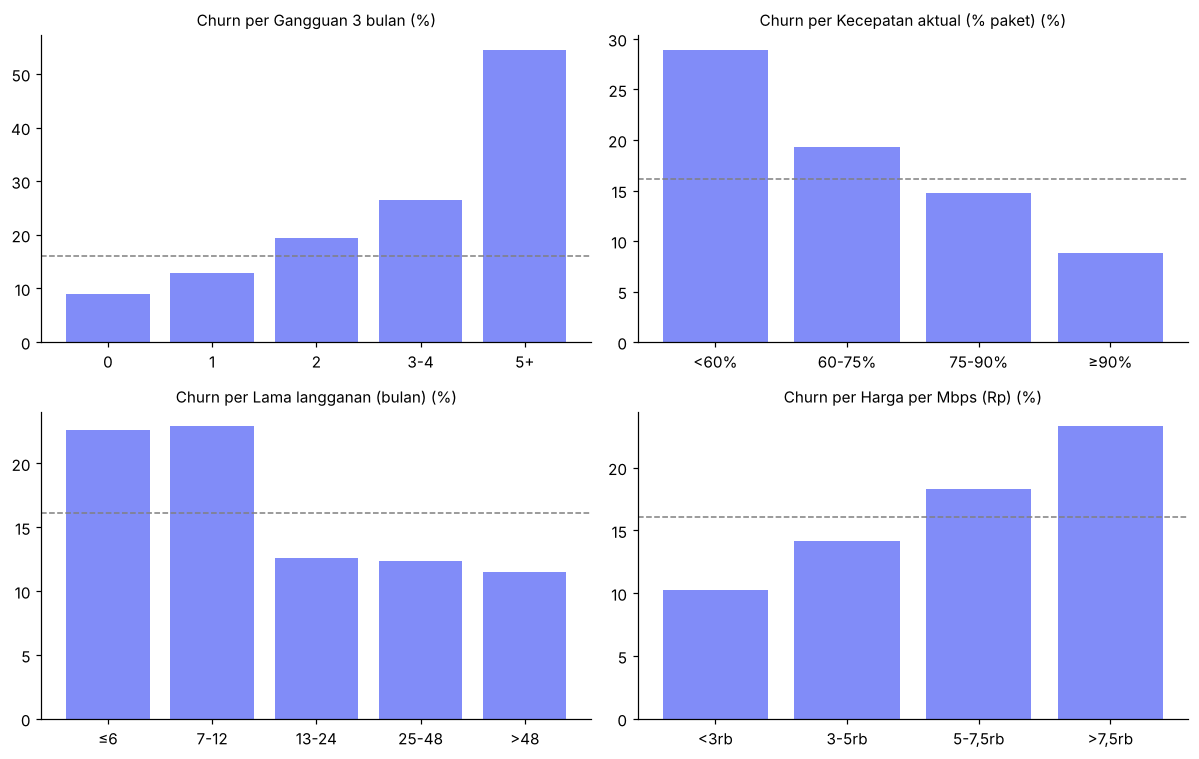

In [4]:
df['harga_per_mbps'] = df.tagihan_bulanan / df.paket_mbps
bins = {
    'Gangguan 3 bulan': pd.cut(df.gangguan_3bln, [-1, 0, 1, 2, 4, 50], labels=['0', '1', '2', '3-4', '5+']),
    'Kecepatan aktual (% paket)': pd.cut(df.kecepatan_aktual_pct, [0, 60, 75, 90, 200], labels=['<60%', '60-75%', '75-90%', '≥90%']),
    'Lama langganan (bulan)': pd.cut(df.lama_langganan_bulan, [0, 6, 12, 24, 48, 200], labels=['≤6', '7-12', '13-24', '25-48', '>48']),
    'Harga per Mbps (Rp)': pd.cut(df.harga_per_mbps, [0, 3000, 5000, 7500, 100000], labels=['<3rb', '3-5rb', '5-7,5rb', '>7,5rb']),
}
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, (judul, b) in zip(ax.flat, bins.items()):
    r = df.groupby(b, observed=True).churn.mean() * 100
    a.bar(r.index.astype(str), r.values, color='#818cf8'); a.axhline(df.churn.mean() * 100, ls='--', c='grey', lw=1)
    a.set_title(f'Churn per {judul} (%)', fontsize=10)
plt.tight_layout(); plt.show()

**Temuan EDA:**
- **Gangguan** adalah sinyal terkuat: pelanggan dengan 5+ gangguan dalam 3 bulan churn >50%.
- Area yang sudah dimasuki **paket 100 Mbps Rp100 ribu** churn jauh lebih tinggi.
- **Bundling seluler**, **kontrak 24 bulan**, dan **auto-debit** berasosiasi dengan churn rendah; pembayaran di **minimarket** paling tinggi (sering telat bayar → isolir).
- **6 bulan pertama** paling rawan, apalagi saat **harga promo berakhir**.

## 3. Rekayasa fitur
- `harga_per_mbps` (log) — *value for money* lebih bermakna daripada nominal tagihan.
- `kontrak_habis_1bln` — kontrak yang habis bulan ini atau bulan depan.
- `masa_langganan_band` — ≤6 bulan, 7–12, 13–47, ≥48 bulan (hubungan tidak linear).
- `pemakaian_gb_bulan` (log) — pelanggan yang jarang memakai lebih mudah berhenti.

**Tidak dipakai:** data demografis pelanggan (tidak ada di data), dan **kota** (pengaruh lokasi diwakili oleh fitur kompetitor & kualitas jaringan).

In [5]:
def fitur(d):
    o = d.copy()
    o['harga_per_mbps'] = o.tagihan_bulanan / o.paket_mbps
    o['kontrak_habis_1bln'] = (o.sisa_kontrak_bulan.notna() & (o.sisa_kontrak_bulan <= 1)).astype(int)
    o['masa_langganan_band'] = pd.cut(o.lama_langganan_bulan, [0, 6, 12, 47, 1000], labels=['≤6 bln', '7-12 bln', '13-47 bln', '≥48 bln']).astype(str)
    return o

NUM = ['gangguan_3bln', 'rata_jam_perbaikan', 'kecepatan_aktual_pct', 'keluhan_cs_3bln', 'telat_bayar_6bln', 'isolir_6bln', 'skor_kepuasan']
LOG = ['harga_per_mbps', 'pemakaian_gb_bulan']
BIN = ['add_on_tv', 'bundling_seluler', 'promo_baru_berakhir', 'kompetitor_murah_di_area', 'kontrak_habis_1bln']
CAT = ['jenis_kontrak', 'metode_bayar', 'masa_langganan_band']
CAT_ORDER = [['Kontrak 12 bulan', 'Bulanan (tanpa kontrak)', 'Kontrak 24 bulan'],
             ['Virtual account bank', 'Auto-debit / kartu kredit', 'E-wallet', 'Gerai minimarket'],
             ['13-47 bln', '≤6 bln', '7-12 bln', '≥48 bln']]
FEATURES = NUM + LOG + BIN + CAT
X = fitur(df)[FEATURES]; y = df.churn
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train:', X_tr.shape, f'churn {y_tr.mean():.1%} | Test:', X_te.shape, f'churn {y_te.mean():.1%}')

def preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
        ('log', Pipeline([('log', FunctionTransformer(np.log, feature_names_out='one-to-one')), ('sc', StandardScaler())]), LOG),
        ('bin', 'passthrough', BIN),
        ('cat', OneHotEncoder(categories=CAT_ORDER, handle_unknown='ignore', drop='first'), CAT)])

Train: (2400, 17) churn 16.1% | Test: (600, 17) churn 16.2%


## 4. Perbandingan model (5-fold cross-validation pada data latih)

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
kandidat = {
    'Logistic Regression': LogisticRegression(max_iter=3000, C=0.5),
    'Random Forest': RandomForestClassifier(500, min_samples_leaf=5, class_weight='balanced_subsample', random_state=RS, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=RS),
}
hasil, oof_all = [], {}
for nama, m in kandidat.items():
    oof = cross_val_predict(Pipeline([('prep', preprocessor()), ('model', m)]), X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]
    oof_all[nama] = oof
    hasil.append({'Model': nama, 'ROC-AUC': roc_auc_score(y_tr, oof), 'PR-AUC': average_precision_score(y_tr, oof)})
cv_table = pd.DataFrame(hasil).sort_values('ROC-AUC', ascending=False).round(3)
cv_table

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.811,0.497
1,Random Forest,0.789,0.448
2,Gradient Boosting,0.782,0.460


Logistic Regression dipilih karena terbaik di CV sekaligus bisa dijelaskan ke tim CS & marketing, dan bisa dijalankan langsung di browser.

## 5. Ambang keputusan (F1) & evaluasi akhir di data uji

In [7]:
oof = oof_all['Logistic Regression']
grid = np.round(np.arange(0.08, 0.61, 0.01), 2)
THRESHOLD = float(grid[int(np.argmax([fbeta_score(y_tr, oof >= t, beta=1) for t in grid]))])
print(f'Ambang {THRESHOLD:.2f} | CV recall {recall_score(y_tr, oof >= THRESHOLD):.1%} | CV precision {precision_score(y_tr, oof >= THRESHOLD):.1%} | ditandai {(oof >= THRESHOLD).mean():.0%}')

final = Pipeline([('prep', preprocessor()), ('model', LogisticRegression(max_iter=3000, C=0.5))]).fit(X_tr, y_tr)
p_te = final.predict_proba(X_te)[:, 1]; pred = (p_te >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
test_metrics = {'roc_auc': roc_auc_score(y_te, p_te), 'pr_auc': average_precision_score(y_te, p_te),
                'recall': recall_score(y_te, pred), 'precision': precision_score(y_te, pred),
                'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn), 'base_rate': float(y_te.mean())}
print(f"ROC-AUC {test_metrics['roc_auc']:.3f} | PR-AUC {test_metrics['pr_auc']:.3f} (acak = {y_te.mean():.3f}) | recall {test_metrics['recall']:.1%} | precision {test_metrics['precision']:.1%}")
pd.DataFrame([[tn, fp], [fn, tp]], index=['Aktual: bertahan', 'Aktual: churn'], columns=['Prediksi: aman', 'Prediksi: berisiko'])

Ambang 0.24 | CV recall 58.0% | CV precision 43.5% | ditandai 21%
ROC-AUC 0.783 | PR-AUC 0.443 (acak = 0.162) | recall 51.5% | precision 36.0%


,Prediksi: aman,Prediksi: berisiko
Aktual: bertahan,414,89
Aktual: churn,47,50


Fokus ke 10% pelanggan berisiko tertinggi -> menangkap 31% yang churn
Fokus ke 20% pelanggan berisiko tertinggi -> menangkap 45% yang churn
Fokus ke 30% pelanggan berisiko tertinggi -> menangkap 63% yang churn
Fokus ke 40% pelanggan berisiko tertinggi -> menangkap 75% yang churn
Fokus ke 50% pelanggan berisiko tertinggi -> menangkap 87% yang churn


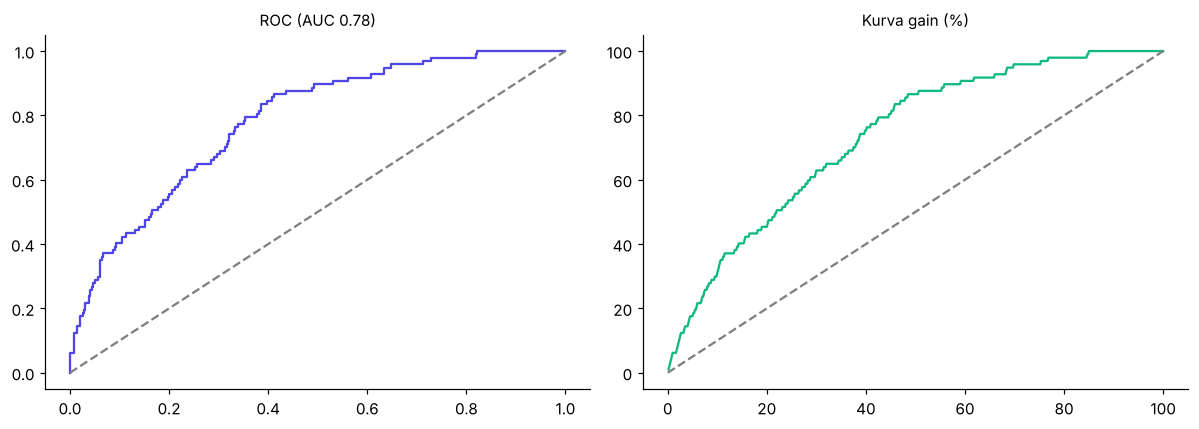

In [8]:
order = np.argsort(-p_te); cum = np.cumsum(y_te.values[order]) / y_te.sum(); pct = np.arange(1, len(order) + 1) / len(order)
gain = {int(k): float(cum[int(np.ceil(k / 100 * len(order))) - 1]) for k in [10, 20, 30, 40, 50]}
for k, v in gain.items(): print(f'Fokus ke {k:>2}% pelanggan berisiko tertinggi -> menangkap {v:.0%} yang churn')
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0].plot(fpr, tpr, c='#4f46e5'); ax[0].plot([0, 1], [0, 1], ls='--', c='grey'); ax[0].set_title(f"ROC (AUC {test_metrics['roc_auc']:.2f})", fontsize=10)
ax[1].plot(pct * 100, cum * 100, c='#10b981'); ax[1].plot([0, 100], [0, 100], ls='--', c='grey'); ax[1].set_title('Kurva gain (%)', fontsize=10)
plt.tight_layout(); plt.show()

## 6. Faktor pendorong churn

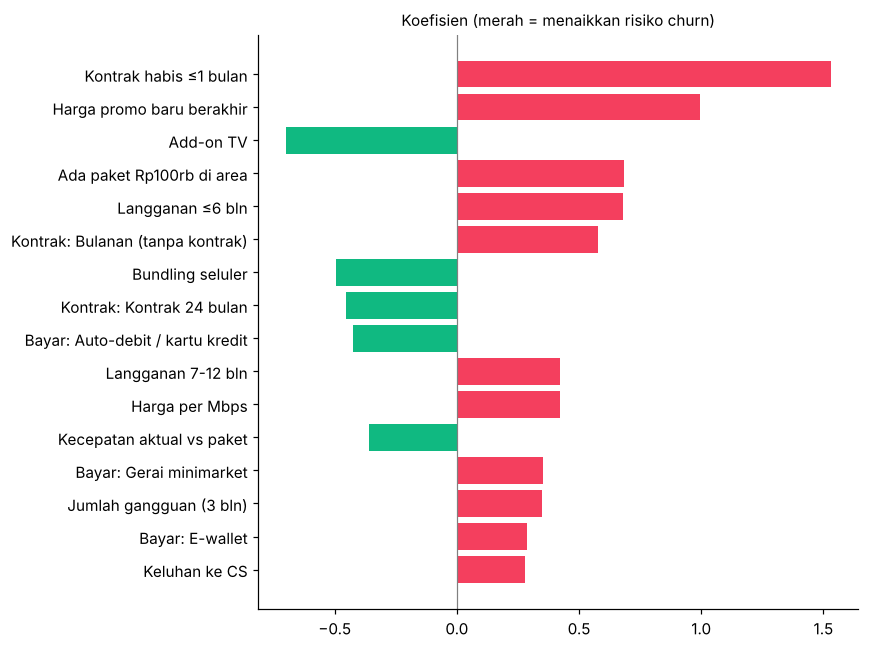

,faktor,koef,odds_ratio
0,Kontrak habis ≤1 bulan,1.53,4.62
1,Harga promo baru berakhir,0.99,2.70
2,Add-on TV,-0.70,0.50
3,Ada paket Rp100rb di area,0.68,1.98
4,Langganan ≤6 bln,0.68,1.97
5,Kontrak: Bulanan (tanpa kontrak),0.58,1.78
6,Bundling seluler,-0.50,0.61
7,Kontrak: Kontrak 24 bulan,-0.45,0.63
8,Bayar: Auto-debit / kartu kredit,-0.43,0.65
9,Langganan 7-12 bln,0.42,1.53


In [9]:
prep, lr = final.named_steps['prep'], final.named_steps['model']
names = prep.get_feature_names_out(); coef = pd.Series(lr.coef_[0], index=names)
LABEL = {'gangguan_3bln': 'Jumlah gangguan (3 bln)', 'rata_jam_perbaikan': 'Lama perbaikan gangguan', 'kecepatan_aktual_pct': 'Kecepatan aktual vs paket',
         'keluhan_cs_3bln': 'Keluhan ke CS', 'telat_bayar_6bln': 'Telat bayar', 'isolir_6bln': 'Pernah diisolir', 'skor_kepuasan': 'Skor kepuasan',
         'harga_per_mbps': 'Harga per Mbps', 'pemakaian_gb_bulan': 'Pemakaian data', 'add_on_tv': 'Add-on TV', 'bundling_seluler': 'Bundling seluler',
         'promo_baru_berakhir': 'Harga promo baru berakhir', 'kompetitor_murah_di_area': 'Ada paket Rp100rb di area', 'kontrak_habis_1bln': 'Kontrak habis ≤1 bulan'}
def label(n):
    raw = n.split('__', 1)[1]
    for pre, lab in [('jenis_kontrak_', 'Kontrak: '), ('metode_bayar_', 'Bayar: '), ('masa_langganan_band_', 'Langganan ')]:
        if raw.startswith(pre): return lab + raw[len(pre):]
    return LABEL.get(raw, raw)
drivers = pd.DataFrame({'faktor': [label(n) for n in names], 'koef': coef.values, 'odds_ratio': np.exp(coef.values)})
drivers = drivers.reindex(drivers.koef.abs().sort_values(ascending=False).index).reset_index(drop=True)
top = drivers.head(16).iloc[::-1]
plt.figure(figsize=(8, 6)); plt.barh(top.faktor, top.koef, color=['#f43f5e' if k > 0 else '#10b981' for k in top.koef])
plt.axvline(0, c='grey', lw=.8); plt.title('Koefisien (merah = menaikkan risiko churn)', fontsize=10); plt.tight_layout(); plt.show()
drivers.head(16).round(2)

## 7. Dampak bisnis: pendapatan berisiko

In [10]:
d_all = fitur(df)
d_all['p_churn'] = final.predict_proba(d_all[FEATURES])[:, 1]
d_all['pendapatan_berisiko_tahunan'] = d_all.p_churn * d_all.tagihan_bulanan * 12
tot = d_all.tagihan_bulanan.sum() * 12
risk = d_all.pendapatan_berisiko_tahunan.sum()
flag = d_all.p_churn >= THRESHOLD
print(f"Pendapatan tahunan basis pelanggan : Rp{tot/1e9:,.2f} miliar")
print(f"Pendapatan berisiko (expected)     : Rp{risk/1e9:,.2f} miliar ({risk/tot:.1%})")
print(f"Pelanggan di atas ambang           : {flag.sum():,} ({flag.mean():.0%}) — menyumbang {d_all.loc[flag, 'pendapatan_berisiko_tahunan'].sum()/risk:.0%} pendapatan berisiko")

Pendapatan tahunan basis pelanggan : Rp9.11 miliar
Pendapatan berisiko (expected)     : Rp1.38 miliar (15.2%)
Pelanggan di atas ambang           : 664 (22%) — menyumbang 59% pendapatan berisiko


**Rekomendasi untuk NusaNet:**
1. **Perbaiki pengalaman gangguan** — pelanggan dengan gangguan berulang & perbaikan > 24 jam adalah prioritas tim teknis (proaktif hubungi sebelum mereka komplain).
2. **Tawarkan bundling seluler / kontrak 24 bulan** kepada pelanggan bulanan berisiko — keduanya berasosiasi dengan churn lebih rendah.
3. **Migrasi ke auto-debit** untuk pelanggan yang sering telat bayar di minimarket (mengurangi isolir).
4. **Respons perang harga secara selektif** — upgrade kecepatan untuk pelanggan berisiko di area yang dimasuki paket Rp100 ribu, bukan potong harga massal.
5. **Program 6 bulan pertama** & transisi akhir promo (hubungi sebelum harga normal berlaku).

## 8. Ekspor model untuk aplikasi web

In [11]:
imp = prep.named_transformers_['num'].named_steps['imp']; sc = prep.named_transformers_['num'].named_steps['sc']
sl = prep.named_transformers_['log'].named_steps['sc']; ohe = prep.named_transformers_['cat']
model_json = {
    'intercept': float(lr.intercept_[0]), 'threshold': THRESHOLD, 'base_rate': float(y.mean()),
    'num': [{'name': n, 'median': float(m_), 'mean': float(m), 'scale': float(s), 'coef': float(coef['num__' + n])} for n, m_, m, s in zip(NUM, imp.statistics_, sc.mean_, sc.scale_)],
    'log': [{'name': n, 'mean': float(m), 'scale': float(s), 'coef': float(coef['log__' + n])} for n, m, s in zip(LOG, sl.mean_, sl.scale_)],
    'bin': [{'name': n, 'coef': float(coef['bin__' + n]), 'mean': float(X_tr[n].mean())} for n in BIN],
    'cat': [{'name': n, 'base': str(cats[0]), 'coef': {str(c): float(coef[f'cat__{n}_{c}']) for c in cats[1:]},
             'mean': {str(c): float((X_tr[n].astype(str) == str(c)).mean()) for c in cats[1:]}} for n, cats in zip(CAT, ohe.categories_)],
}
def rate_list(s):
    g = d_all.groupby(s, observed=True).churn.agg(['size', 'mean'])
    return [{'k': str(k), 'n': int(n), 'r': float(r)} for k, (n, r) in g.iterrows()]
fpr, tpr, _ = roc_curve(y_te, p_te); idx = np.unique(np.linspace(0, len(fpr) - 1, 60).astype(int))
report = {
    'n': len(df), 'n_churn': int(y.sum()), 'n_train': len(X_tr), 'n_test': len(X_te),
    'cv': cv_table.to_dict('records'), 'test': test_metrics, 'gain': gain,
    'gain_curve': [[round(float(a) * 100, 1), round(float(b) * 100, 1)] for a, b in zip(pct[::3], cum[::3])],
    'roc': [[round(float(fpr[i]), 3), round(float(tpr[i]), 3)] for i in idx],
    'drivers': drivers.head(16).round(3).to_dict('records'),
    'eda': {'kontrak': rate_list('jenis_kontrak'), 'bayar': rate_list('metode_bayar'),
            'kompetitor': rate_list(d_all.kompetitor_murah_di_area.map({0: 'Tidak ada', 1: 'Ada paket Rp100rb'})),
            'bundling': rate_list(d_all.bundling_seluler.map({0: 'Internet saja', 1: 'Bundling seluler'})),
            'gangguan': rate_list(bins['Gangguan 3 bulan']), 'kecepatan': rate_list(bins['Kecepatan aktual (% paket)']),
            'tenure': rate_list(bins['Lama langganan (bulan)']), 'harga': rate_list(bins['Harga per Mbps (Rp)'])},
    'paket': {str(k): int(v) for k, v in df.groupby('paket_mbps').tagihan_bulanan.median().items()},
}
json.dump({'model': model_json, 'report': report}, open('churn_model.json', 'w'), ensure_ascii=False, indent=1)

def score(r):
    z = model_json['intercept']
    for f in model_json['num']:
        v = r[f['name']]; v = f['median'] if pd.isna(v) else v
        z += f['coef'] * (v - f['mean']) / f['scale']
    for f in model_json['log']: z += f['coef'] * (np.log(r[f['name']]) - f['mean']) / f['scale']
    for f in model_json['bin']: z += f['coef'] * r[f['name']]
    for f in model_json['cat']: z += f['coef'].get(str(r[f['name']]), 0.0)
    return 1 / (1 + np.exp(-z))
print('Selisih maks JSON vs sklearn:', float(np.abs(np.array([score(r) for _, r in X_te.iterrows()]) - p_te).max()))

Selisih maks JSON vs sklearn: 3.3306690738754696e-16


## 9. Kesimpulan & batasan
- Model churn yang bisa dijelaskan memprioritaskan pelanggan berisiko dan mengukur **pendapatan yang terancam dalam Rupiah**, sehingga tim retensi bisa fokus pada pelanggan bernilai tinggi.
- **Batasan:** data sintetis — efek tiap faktor berasal dari asumsi kalibrasi. Untuk dipakai sungguhan, pipeline dilatih ulang dengan data billing, tiket gangguan, dan network monitoring ISP, lalu efektivitas kampanye retensi diuji dengan A/B test.